In [16]:
import pickle
import sys
import pandas as pd
import anndata as ad
import numpy as np
sys.path.append('/home/jwinchel/Syndri/Heimdall/')

# from Heimdall.utils import convert_to_ensembl_ids
# load transcript data
tx_df = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep2/Lung5_Rep2-Flat_files_and_images/Lung5_Rep2_tx_file.csv')

# Unpickling (loading from a file)
with open('/home/jwinchel/Syndri/nsclc_playground/gene_mapping.pickle', 'rb') as f:
    gene_mapping = pickle.load(f)


tx_df['gene_id_ensembl'] = tx_df['target'].map(gene_mapping.mapping_full)
tx_df['gene_id_ensembl'] = tx_df['gene_id_ensembl'].apply(lambda x: x[0] if isinstance(x,list) else x)
# cell_df = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_metadata_file.csv')
st_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/cosmx_nsclc_Lung5-Rep2_adata_annotated_med_with_admix_probs.h5ad')
# l5r1_metadata = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_metadata_file.csv')

st_data = st_data[st_data.obs['Run_Tissue_name']=='Lung5_Rep2']
# st_data.obs = st_data.obs.merge(l5r1_metadata[['fov','cell_ID','CenterX_local_px',
#        'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px']],on=['fov','cell_ID'],how='left')
st_data.obs['cell_type'] = st_data.obs['cell_type'].astype(str)
st_data.obs.loc[st_data.obs['cell_type'].str.startswith('tumor'),'cell_type'] = 'tumor'

# load a single fov
tx_df = tx_df[tx_df['fov'].isin(list(np.arange(20,30)))].reset_index(drop=True)
# cell_df = cell_df[cell_df['fov'] == 26].reset_index(drop=True)
# cell_df.head()

/tmp/ipykernel_3351208/3633996913.py:26: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  st_data.obs['cell_type'] = st_data.obs['cell_type'].astype(str)


In [17]:
st_data.obs

,fov,cell_ID,tissue,CenterX_local_px,CenterY_local_px,CenterX_global_px,CenterY_global_px,sdimx,sdimy,cell_ID_long,...,log10totalcounts,background,remove_flagged_cells,patient,cell_type_orig,niche,prop_tumor_in_100_neighbors,cell_type,batch,split
257211,1,1,Lung5_Rep2,806.0,3628.0,8156.000000,162800.222222,0.14508,-18.97060,c_2_1_1,...,2.071882,0.025428,False,Lung5,tumor 5,tumor-stroma boundary,0.56,tumor,st,val
257213,1,3,Lung5_Rep2,1637.0,3607.0,8987.000000,162779.222222,0.29466,-18.97438,c_2_1_3,...,2.451786,0.060983,False,Lung5,mast,plasmablast-enriched stroma,0.01,mast,st,val
257214,1,4,Lung5_Rep2,1694.0,3619.0,9044.000000,162791.222222,0.30492,-18.97222,c_2_1_4,...,2.000000,0.021549,False,Lung5,neutrophil,stroma,0.02,neutrophil,st,val
257215,1,5,Lung5_Rep2,1869.0,3596.0,9219.000000,162768.222222,0.33642,-18.97636,c_2_1_5,...,2.274158,0.040512,False,Lung5,tumor 12,stroma,0.02,tumor,st,val
257216,1,6,Lung5_Rep2,2208.0,3617.0,9558.000000,162789.222222,0.39744,-18.97258,c_2_1_6,...,1.934498,0.018532,False,Lung5,tumor 13,plasmablast-enriched stroma,0.02,tumor,st,val
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
363893,30,4161,Lung5_Rep2,1072.0,20.0,30310.888889,177442.222222,4.13296,-16.33504,c_2_30_4161,...,2.181844,0.032754,False,Lung5,fibroblast,stroma,0.00,fibroblast,st,val
363894,30,4162,Lung5_Rep2,1179.0,18.0,30417.888889,177440.222222,4.15222,-16.33540,c_2_30_4162,...,2.082785,0.026074,False,Lung5,fibroblast,stroma,0.00,fibroblast,st,val
363895,30,4163,Lung5_Rep2,1323.0,16.0,30561.888889,177438.222222,4.17814,-16.33576,c_2_30_4163,...,1.397940,0.005387,False,Lung5,fibroblast,stroma,0.00,fibroblast,st,val
363896,30,4164,Lung5_Rep2,3080.0,12.0,32318.888889,177434.222222,4.49440,-16.33648,c_2_30_4164,...,1.431364,0.005818,False,Lung5,plasmablast,stroma,0.00,plasmablast,st,val


In [18]:
from scipy import sparse
import numpy as np
def gene_cell_admix_df(
    adata,
    probs_layer="admix_probs",
    thr=0.5,
    use_nonzero_only=True,
):
    """
    Returns a long dataframe with columns:
      cell, gene, prob, is_admixed, status
    If use_nonzero_only=True, restrict to entries where X > 0 (i.e., observed transcripts).
    """
    probs = adata.layers[probs_layer]
    if sparse.issparse(probs):
        probs = probs.toarray()

    X = adata.X
    if sparse.issparse(X):
        X = X.tocsr()

    cells = np.asarray(adata.obs_names)
    genes = np.asarray(adata.var_names)

    if use_nonzero_only:
        if not sparse.issparse(adata.X):
            nz = np.nonzero(X)
            r, c = nz
        else:
            r, c = X.nonzero()

        df = pd.DataFrame({
            "cell": adata.obs['cell_ID'].values[r],
            "fov": adata.obs['fov'].values[r],
            "gene": genes[c],
            "prob": probs[r, c],
            "cell_type": adata.obs['cell_type'].values[r],
        })
    else:
        # WARNING: can be huge (n_cells * n_genes)
        r, c = np.indices(probs.shape)
        df = pd.DataFrame({
            "cell": cells[r.ravel()],
            "gene": genes[c.ravel()],
            "prob": probs.ravel(),
        })

    df["is_admixed"] = df["prob"] > thr
    df["status"] = np.where(df["is_admixed"], "admixed", "kept")
    return df

gene_cell_df = gene_cell_admix_df(st_data, probs_layer="admix_probs", thr=0.65, use_nonzero_only=True)

In [4]:
# tx_df = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_tx_file.csv')

# # Unpickling (loading from a file)
# with open('/home/jwinchel/Syndri/nsclc_playground/gene_mapping.pickle', 'rb') as f:
#     gene_mapping = pickle.load(f)


# tx_df['gene_id_ensembl'] = tx_df['target'].map(gene_mapping.mapping_full)
# tx_df['gene_id_ensembl'] = tx_df['gene_id_ensembl'].apply(lambda x: x[0] if isinstance(x,list) else x)

In [19]:
tx_df[['fov','cell_ID','gene_id_ensembl']].dtypes, gene_cell_df[['fov','cell','gene']].dtypes

(fov                 int64
 cell_ID             int64
 gene_id_ensembl    object
 dtype: object,
 fov        int64
 cell    category
 gene      object
 dtype: object)

In [20]:
gene_cell_df['cell'] = gene_cell_df['cell'].astype(int)
tx_df = tx_df.merge(gene_cell_df, left_on=['fov','cell_ID','gene_id_ensembl'], right_on=['fov','cell','gene'], how='left')

In [21]:
tx_df['status'].dropna()

248384      kept
248385      kept
248386      kept
248387      kept
248388      kept
            ... 
12173962    kept
12173963    kept
12173964    kept
12173965    kept
12173966    kept
Name: status, Length: 9546336, dtype: object

In [22]:
tx_df[['fov','cell_ID']].dtypes, st_data.obs[['fov','cell_ID']].dtypes #[['fov','cell_ID','gene_id_ensembl']].dtypes,gene_cell_df[['fov','cell','gene']].dtypes

(fov        int64
 cell_ID    int64
 dtype: object,
 fov           int64
 cell_ID    category
 dtype: object)

In [23]:
st_data.obs['cell_ID'] = st_data.obs['cell_ID'].astype(int)
tx_df = tx_df.merge(st_data.obs[['fov','cell_ID','CenterX_global_px','CenterY_global_px','Width','Height']], left_on=['fov','cell_ID'], right_on=['fov','cell_ID'], how='left')

In [10]:
# tx_df = tx_df.drop(columns=['CenterX_global_px','CenterY_global_px','Width','Height'])

In [24]:
tx_df[['fov','cell_ID']].dtypes,st_data.obs[['fov','cell_ID']].dtypes

(fov        int64
 cell_ID    int64
 dtype: object,
 fov        int64
 cell_ID    int64
 dtype: object)

In [12]:
# tx_df[['cell_type_x']].dropna()

In [25]:
tx_df["dx"] = tx_df["x_global_px"] - tx_df["CenterX_global_px"]
tx_df["dy"] = tx_df["y_global_px"] - tx_df["CenterY_global_px"]

tx_df["a"] = tx_df["Width"] / 2
tx_df["b"] = tx_df["Height"] / 2

tx_df["r_norm"] = np.sqrt(
    (tx_df["dx"] / tx_df["a"])**2 +
    (tx_df["dy"] / tx_df["b"])**2
)

In [26]:
rad_prob_df = tx_df.dropna().groupby(['cell_type','fov','cell_ID','status'])[['prob','r_norm']].mean()

In [12]:
tx_df['is_admixed'].unique()

array([nan, False, True], dtype=object)

In [27]:
import numpy as np
import pandas as pd

bins = np.linspace(0, 1, 10)

if "cell_ID_long" not in tx_df.columns:
    if {"fov", "cell_ID"}.issubset(tx_df.columns):
        tx_df["cell_ID_long"] = tx_df["fov"].astype(str) + "_" + tx_df["cell_ID"].astype(str)
    else:
        raise ValueError("Expected cell_ID_long or both fov and cell_ID columns for cell-wise error bars.")

tx_df["radial_bin"] = pd.cut(tx_df["r_norm"], bins=bins, include_lowest=True)

cell_admixed = (
    tx_df
    .dropna(subset=["cell_type", "radial_bin", "cell_ID_long"])
    .groupby(["cell_type", "radial_bin", "cell_ID_long"], observed=True)
    .agg(
        cell_frac_admixed=("is_admixed", "mean"),
        transcript_count=("is_admixed", "size"),
    )
    .reset_index()
)

enrichment = (
    cell_admixed
    .groupby(["cell_type", "radial_bin"], observed=True)
    .agg(
        frac_admixed=("cell_frac_admixed", "mean"),
        cell_frac_admixed_std=("cell_frac_admixed", "std"),
        n_cells=("cell_ID_long", "nunique"),
        transcript_count=("transcript_count", "sum"),
    )
    .reset_index()
)

enrichment["cell_frac_admixed_sem"] = (
    enrichment["cell_frac_admixed_std"] / np.sqrt(enrichment["n_cells"])
).fillna(0)

# Preserve the previous count column name as the total transcript count per cell type/bin.
enrichment["count"] = enrichment["transcript_count"]
enrichment["bin_center"] = enrichment["radial_bin"].apply(lambda interval: (interval.left + interval.right) / 2)


In [28]:
# enrichment = enrichment.rename(columns={'cell_type_x':'cell_type'})
# enrichment

Text(0.5, 1.0, 'Mean Cell-wise Fraction of Admixed Transcripts vs Approximate Radial Position')

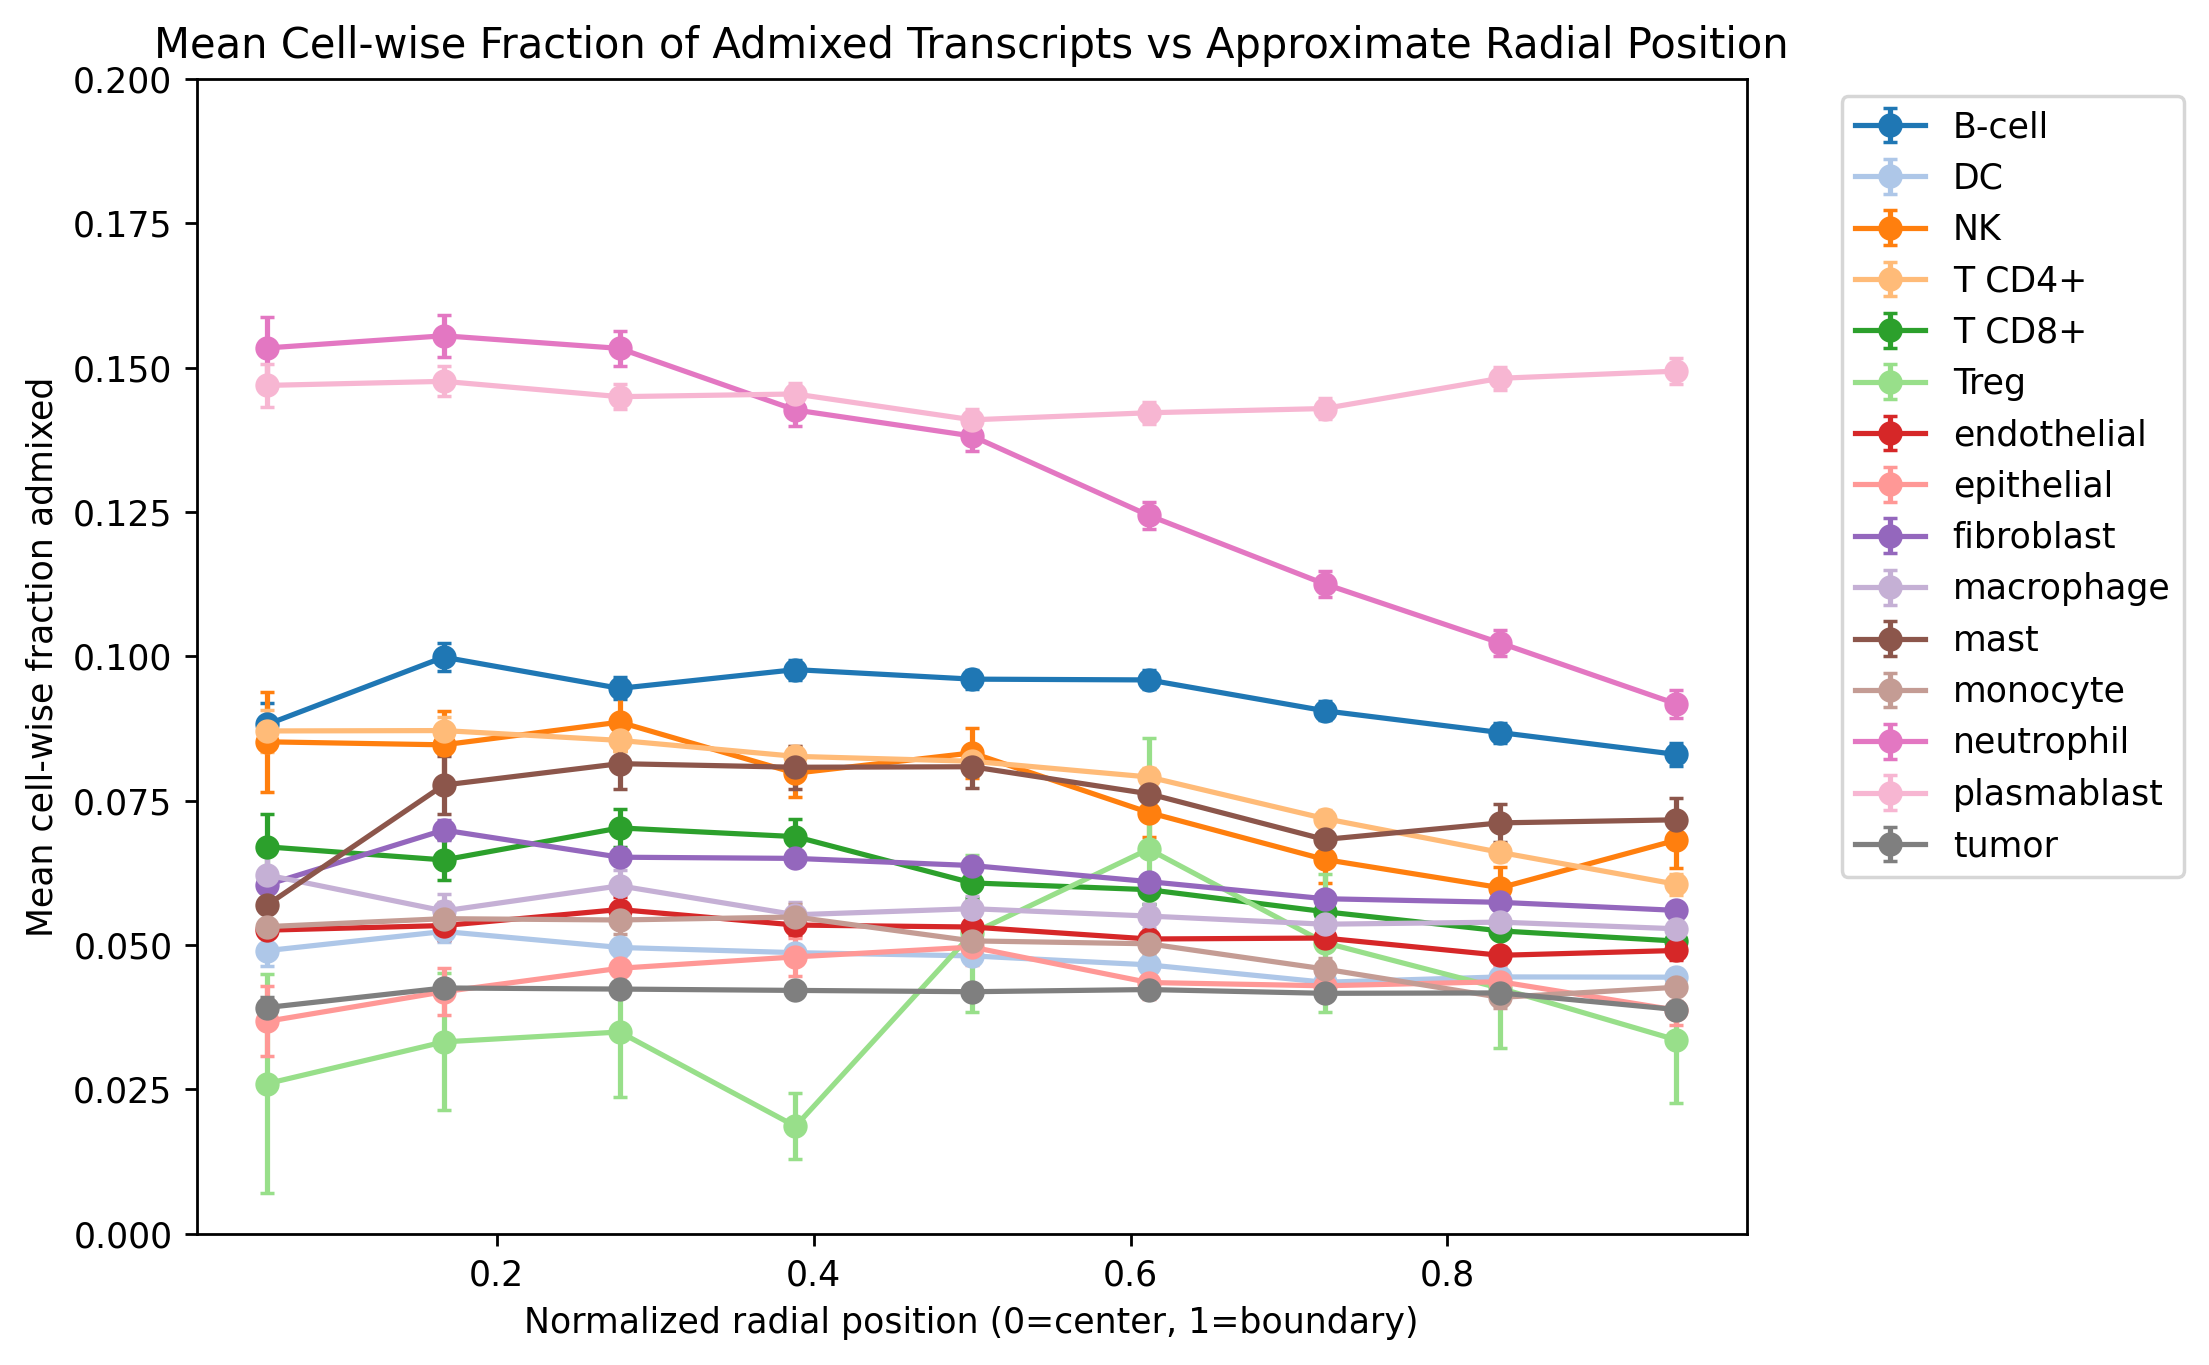

In [29]:
import matplotlib.pyplot as plt

cmap = plt.get_cmap('tab20')
cell_types = enrichment['cell_type'].dropna().unique()
ct_colors = {ct: cmap(i) for i, ct in enumerate(cell_types)}

fig, ax = plt.subplots(figsize=(8, 6), dpi=250)
for cell_type in cell_types:
    subset = (
        enrichment[enrichment['cell_type'] == cell_type]
        .dropna(subset=["bin_center", "frac_admixed"])
        .sort_values("bin_center")
    )
    ax.errorbar(
        subset["bin_center"],
        subset["frac_admixed"],
        yerr=subset["cell_frac_admixed_sem"],
        marker="o",
        capsize=2,
        linewidth=1.5,
        label=cell_type,
        color=ct_colors[cell_type],
    )

ax.set_xlabel("Normalized radial position (0=center, 1=boundary)")
ax.set_ylabel("Mean cell-wise fraction admixed")
ax.set_ylim(0, 0.2)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.set_title('Mean Cell-wise Fraction of Admixed Transcripts vs Approximate Radial Position')
